# EDA — Revenue data
This notebook documents data quality and four visualizations before modelling.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
df=pd.read_csv("../data/output/4 revenue_total.csv",parse_dates=["invoice_date"])


## 1. Total revenue time series
Interpretation: the chart shows the daily revenue level and its gradual growth.

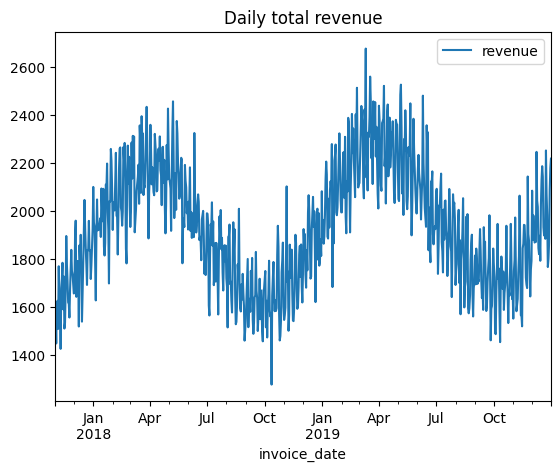

In [2]:
df.plot(x="invoice_date",y="revenue",title="Daily total revenue"); plt.show()

## 2. Trend, seasonality and residual
Interpretation: decomposition separates structural trend from recurring calendar movement and unexplained noise.

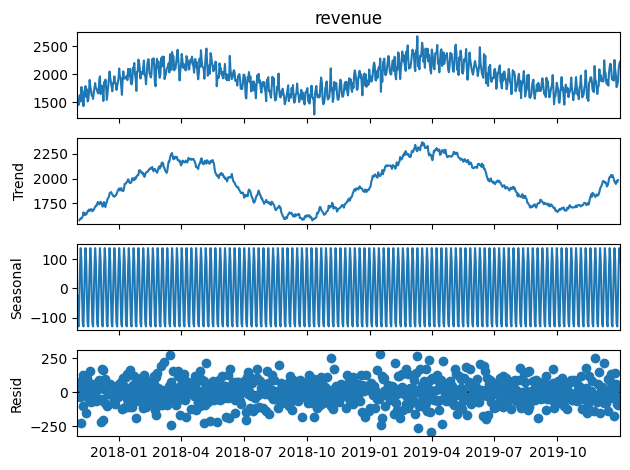

In [3]:
decomp=seasonal_decompose(df.set_index("invoice_date")["revenue"],period=7,model="additive"); decomp.plot(); plt.show()

## 3. ACF / PACF
Interpretation: short lags with significant autocorrelation motivate low-order ARIMA terms; orders are validated in the results notebook.

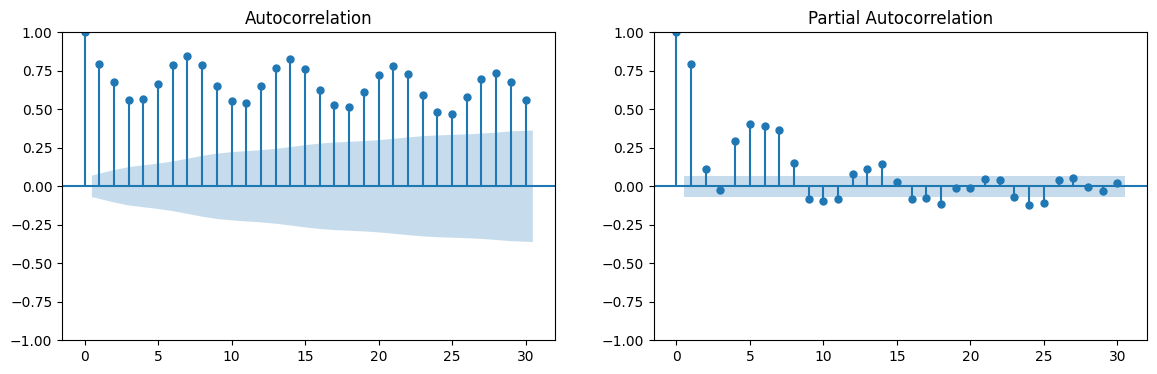

In [4]:
fig,ax=plt.subplots(1,2,figsize=(14,4)); plot_acf(df.revenue,lags=30,ax=ax[0]); plot_pacf(df.revenue,lags=30,ax=ax[1]); plt.show()

## 4. Country comparison
Interpretation: the country chart identifies dominant markets and allows volatility comparisons.

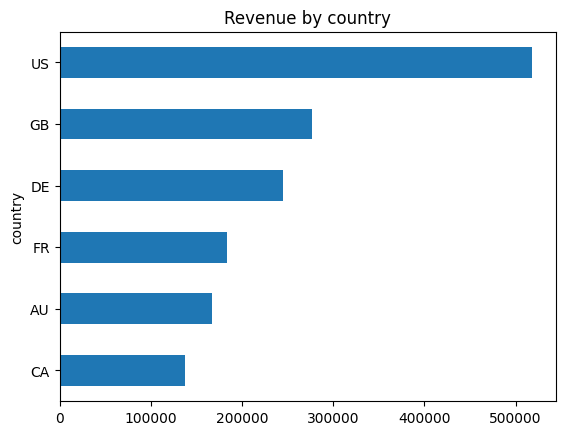

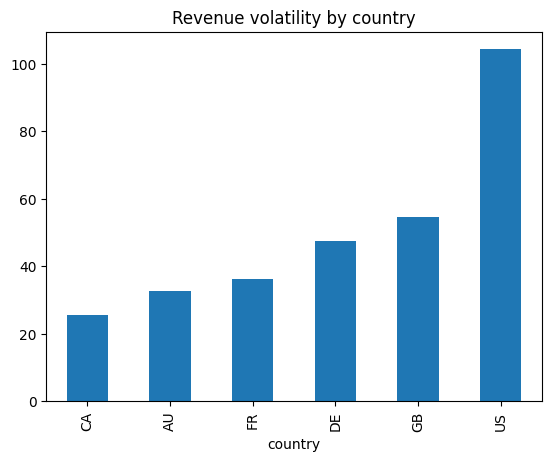

In [5]:
country=pd.read_csv("../data/output/3 revenue_country.csv"); country.groupby("country").revenue.sum().sort_values().plot.barh(title="Revenue by country"); plt.show(); country.groupby("country").revenue.std().sort_values().plot.bar(title="Revenue volatility by country"); plt.show()

## Data quality
Invalid dates, countries, and amounts are dropped in `src/ingest.py`; the output row counts are logged.